In [1]:
# Install all required libraries silently
!pip install torch torchvision torchaudio torch-geometric opencv-python moviepy tqdm einops transformers sentencepiece --quiet


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.4/64.4 kB 756.9 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 6.6 MB/s eta 0:00:00


In [2]:
# Import PyTorch base modules
import torch
import torch.nn as nn
import torch.nn.functional as F

# Import graph utilities from PyTorch Geometric
from torch_geometric.data import Data
from torch_geometric.nn import GATConv

# Import pretrained image models from torchvision
import torchvision.models as models

# Import OpenCV for frame extraction
import cv2
import os
import numpy as np

# MoviePy for writing summary video
from moviepy.editor import VideoFileClip, ImageSequenceClip

# tqdm for progress bar
from tqdm import tqdm

# Cosine similarity for graph edges
from sklearn.metrics.pairwise import cosine_similarity

# Colab utilities for uploading files
from google.colab import files
from IPython.display import Video as IPVideo, display

# BLIP image captioning
from transformers import BlipProcessor, BlipForConditionalGeneration

# KMeans for caption clustering
from sklearn.cluster import KMeans

# Set GPU if available
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print("Using device:", device)


/usr/local/lib/python3.13/dist-packages/moviepy/config_defaults.py:47: SyntaxWarning: invalid escape sequence '\P'
  IMAGEMAGICK_BINARY = r"C:\Program Files\ImageMagick-6.8.8-Q16\magick.exe"
/usr/local/lib/python3.13/dist-packages/moviepy/video/io/ffmpeg_reader.py:294: SyntaxWarning: invalid escape sequence '\d'
  lines_video = [l for l in lines if ' Video: ' in l and re.search('\d+x\d+', l)]
/usr/local/lib/python3.13/dist-packages/moviepy/video/io/ffmpeg_reader.py:367: SyntaxWarning: invalid escape sequence '\d'
  rotation_lines = [l for l in lines if 'rotate          :' in l and re.search('\d+$', l)]
/usr/local/lib/python3.13/dist-packages/moviepy/video/io/ffmpeg_reader.py:370: SyntaxWarning: invalid escape sequence '\d'
  match = re.search('\d+$', rotation_line)
  if event.key is 'enter':

  from pkg_resources import resource_stream, resource_exists



Using device: cpu


In [3]:
# Open upload window in Google Colab
uploaded = files.upload()

# Extract filename from uploaded dictionary
video_path = list(uploaded.keys())[0]
print("Uploaded:", video_path)

# Display uploaded video inline
display(IPVideo(video_path, embed=True))

# Load video using MoviePy to obtain duration
input_clip = VideoFileClip(video_path)
input_duration = input_clip.duration

print(f"Original Duration: {input_duration:.2f} seconds")


Saving Bhxk-O1Y7Ho.mp4 to Bhxk-O1Y7Ho.mp4
Uploaded: Bhxk-O1Y7Ho.mp4


Original Duration: 450.84 seconds


In [4]:
# Create folder to store frames
os.makedirs("frames", exist_ok=True)

# Open video file
cap = cv2.VideoCapture(video_path)

# Get original video FPS
fps = cap.get(cv2.CAP_PROP_FPS)

# Extract frames at 2 FPS → sample every X frames
sample_rate = int(max(1, fps // 2))

frames = []  # list to store extracted frames
count = 0    # frame counter

# Loop through video
while True:
    ret, frame = cap.read()  # read next frame
    if not ret:
        break  # end of video

    # Save only frames at sampling interval
    if count % sample_rate == 0:
        frame = cv2.resize(frame, (224,224))  # resize for model input
        frames.append(frame)

    count += 1

cap.release()

print(f"Extracted {len(frames)} frames")


Extracted 966 frames


In [5]:
# Load ConvNeXt-Tiny pretrained on ImageNet
backbone = models.convnext_tiny(weights="IMAGENET1K_V1").features.to(device)
backbone.eval()  # disable training behaviors

def get_embedding(img):
    """Returns a 768-dimensional feature embedding from ConvNeXt"""

    # Convert BGR → RGB
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    # Convert to tensor (C,H,W) and normalize to [0,1]
    img = torch.tensor(img).permute(2,0,1).unsqueeze(0).float() / 255.0

    # Ensure 224×224 resolution
    img = F.interpolate(img, (224,224)).to(device)

    # Extract conv features
    with torch.no_grad():
        feat = backbone(img)

    # Global average pooling
    return torch.mean(feat.flatten(2), dim=2).squeeze(0)

embeddings = []

# Generate embedding for each frame
for f in tqdm(frames, desc="Extracting frame features"):
    embeddings.append(get_embedding(f).cpu().numpy())

# Convert list → NumPy array
embeddings = np.stack(embeddings)

print("Embeddings shape:", embeddings.shape)


Downloading: "https://download.pytorch.org/models/convnext_tiny-983f1562.pth" to /root/.cache/torch/hub/checkpoints/convnext_tiny-983f1562.pth


100%|██████████| 109M/109M [00:00<00:00, 146MB/s]
Extracting frame features: 100%|██████████| 966/966 [03:56<00:00,  4.09it/s]

Embeddings shape: (966, 768)


In [6]:
# Number of nearest neighbors for graph edges
k = 5

# Compute cosine similarity between all frames
sim = cosine_similarity(embeddings)

num_frames = len(frames)
edge_index = []  # will hold pairs of connected nodes

for i in range(num_frames):

    # Add temporal edges (i ↔ i+1)
    if i < num_frames - 1:
        edge_index.append([i, i+1])
        edge_index.append([i+1, i])

    # Add k most similar frames
    nn_idx = np.argsort(-sim[i])[:k]
    for j in nn_idx:
        if i != j:
            edge_index.append([i, j])

# Convert list → tensor
edge_index = torch.tensor(edge_index).t().contiguous()

# Create node feature tensor
x = torch.tensor(embeddings, dtype=torch.float)

# Build PyTorch-Geometric Data object
graph_data = Data(x=x, edge_index=edge_index).to(device)

print("Graph:", graph_data)


Graph: Data(x=[966, 768], edge_index=[2, 5794])


In [7]:
class GraphContrastSum(nn.Module):
    """Graph Attention Network with projection head for contrastive learning."""

    def __init__(self, in_dim, hid_dim=256):
        super().__init__()

        # First GAT layer: 4 heads
        self.gat1 = GATConv(in_dim, hid_dim, heads=4, concat=True)

        # Second GAT layer: produces 128-dim output
        self.gat2 = GATConv(hid_dim*4, 128)

        # Projection head for contrastive space
        self.proj = nn.Linear(128, 64)

    def forward(self, data):
        x = F.elu(self.gat1(data.x, data.edge_index))
        x = self.gat2(x, data.edge_index)
        z = F.normalize(self.proj(x), dim=1)
        return z

# Initialize GNN model
model = GraphContrastSum(in_dim=x.shape[1]).to(device)

# Adam optimizer
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

def contrastive_loss(z):
    """Computes simple self-similarity contrastive loss."""
    sim = torch.matmul(z, z.T)
    pos = torch.exp(sim / 0.5)
    neg = torch.exp(sim / 0.5).sum(1, keepdim=True)
    loss = -torch.log(pos.diag() / neg.squeeze(1))
    return loss.mean()

print("Training GNN...")

# Train for 10 epochs
for epoch in range(10):
    model.train()
    optimizer.zero_grad()

    z = model(graph_data)
    loss = contrastive_loss(z)

    loss.backward()
    optimizer.step()

    print(f"Epoch {epoch+1}: loss={loss.item():.4f}")


Training GNN...
Epoch 1: loss=6.7289
Epoch 2: loss=6.6875
Epoch 3: loss=6.3359
Epoch 4: loss=5.8939
Epoch 5: loss=5.8276
Epoch 6: loss=5.7740
Epoch 7: loss=5.6961
Epoch 8: loss=5.6232
Epoch 9: loss=5.5650
Epoch 10: loss=5.5137


In [8]:
# Switch to evaluation mode
model.eval()

# Get final embeddings z for each frame
with torch.no_grad():
    z = model(graph_data)

# Importance = L2 norm of contrastive embeddinga
importance = torch.norm(z, dim=1).cpu().numpy()

# Number of frames to keep (~10%)
top_k = max(1, len(frames) // 10)

# Pick frame indices with highest importance
key_idx = np.argsort(-importance)[:top_k]
key_idx = np.sort(key_idx)  # ensure chronological order

# Extract keyframes
key_frames = [frames[i] for i in key_idx]

print("Selected", len(key_frames), "keyframes")



Selected 96 keyframes


In [9]:
# Load BLIP processor + model
processor = BlipProcessor.from_pretrained("Salesforce/blip-image-captioning-base")
blip_model = BlipForConditionalGeneration.from_pretrained(
    "Salesforce/blip-image-captioning-base"
).to(device)

def caption_frame(img):
    """Generates a natural language caption for a frame using BLIP."""

    # Convert BGR → RGB
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    # Prepare model inputs
    inputs = processor(img_rgb, return_tensors="pt").to(device)

    # Generate caption with beam search
    with torch.no_grad():
        out = blip_model.generate(**inputs, max_new_tokens=30)

    return processor.decode(out[0], skip_special_tokens=True)

captions = []

# Caption each selected keyframe
for frame in tqdm(key_frames, desc="Generating captions"):
    captions.append(caption_frame(frame))


preprocessor_config.json:   0%|          | 0.00/287 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.56k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/506 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

... (3 outputs left out)

Generating captions:   0%|          | 0/96 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  990MB            

model.safetensors: downloading bytes:           |  0.00B            

Generating captions: 100%|██████████| 96/96 [05:15<00:00,  3.29s/it]


In [11]:
# Use ResNet18 as dummy text embedding model (image encoder trick)
text_emb_model = models.resnet18(weights="IMAGENET1K_V1")
text_emb_model.fc = torch.nn.Identity()  # remove classifier
text_emb_model = text_emb_model.to(device)

def text_embed(_):
    """Generate random embedding using image model (placeholder)."""
    t = torch.randn(1, 3, 224, 224).to(device)
    return text_emb_model(t).detach().cpu().numpy().flatten()

# Compute embeddings for each caption
text_embs = np.stack([text_embed(c) for c in captions])

# Number of clusters
num_clusters = min(5, len(captions)//2)

# KMeans clustering
kmeans = KMeans(n_clusters=num_clusters, random_state=0)
cluster_labels = kmeans.fit_predict(text_embs)

# Combine captions into grouped summary
summary_text = ""

for c in range(num_clusters):
    group = [captions[i] for i in range(len(captions)) if cluster_labels[i] == c]
    summary_text += f"• {group[0].capitalize()}\n"

print("\n========== VIDEO SUMMARY ==========")
print(summary_text)


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 111MB/s]



========== VIDEO SUMMARY ==========
• A city skyline at night with light trails
• Just a girl, just a boy
• A woman is brushing her teeth in a bathroom
• A white dog with a black nose
• A woman with long brown hair



In [12]:
# Create output directory
os.makedirs("output", exist_ok=True)

# Path of summary video
summary_path = "output/summary_video.mp4"

# Build video from selected frames (2 FPS)
clip = ImageSequenceClip(
    [cv2.cvtColor(f, cv2.COLOR_BGR2RGB) for f in key_frames],
    fps=2
)

# Save video
clip.write_videofile(summary_path, codec='libx264', audio=False)

# Load summary video to measure duration
summary_clip = VideoFileClip(summary_path)
summary_duration = summary_clip.duration

print("\n========== FINAL RESULTS ==========")
print(f"Original Duration: {input_duration:.2f}s")
print(f"Summary Duration: {summary_duration:.2f}s")
print(f"Compression Ratio: {(summary_duration/input_duration)*100:.2f}%")

# Display final summary video
display(IPVideo(summary_path, embed=True))

print("\n📄 TEXT SUMMARY:")
print(summary_text)


Moviepy - Building video output/summary_video.mp4.
Moviepy - Writing video output/summary_video.mp4



Moviepy - Done !
Moviepy - video ready output/summary_video.mp4

========== FINAL RESULTS ==========
Original Duration: 450.84s
Summary Duration: 48.00s
Compression Ratio: 10.65%



📄 TEXT SUMMARY:
• A city skyline at night with light trails
• Just a girl, just a boy
• A woman is brushing her teeth in a bathroom
• A white dog with a black nose
• A woman with long brown hair



In [13]:
import math  # For numeric operations (optional but safe)

print("\n================= PERFORMANCE METRICS =================")


# --------------------------------------------------------
# 1. Compression Ratio
# --------------------------------------------------------
# Measures how much shorter the summary video is compared to the original.
# Lower compression ratio → more aggressive summarization.
compression_ratio = summary_duration / input_duration

print(
    f"1) Compression Ratio: {compression_ratio*100:.2f}% "
    f"(lower = more compressed)"
)


# --------------------------------------------------------
# 2. Frame Selection Ratio
# --------------------------------------------------------
# Measures how many frames were selected from total extracted frames.
# Lower frame ratio → stronger summarization.
frame_ratio = len(key_frames) / len(frames)

print(
    f"2) Frame Selection Ratio: {frame_ratio*100:.2f}% "
    f"({len(key_frames)} selected from {len(frames)} frames)"
)


# --------------------------------------------------------
# 3. Temporal Coverage Score
# --------------------------------------------------------
# Purpose:
#   Measures how evenly the selected frames are distributed over time.
#
# Method:
#   - Compute gaps (intervals) between consecutive selected frame indices.
#   - High variance between gaps → bad temporal coverage.
#   - Score = 1 - (std / mean)
#   - Score is clipped to [0,1]
#
coverage = 0              # score placeholder
prev_idx = 0              # track previous keyframe index
intervals = []            # list of gaps between selected frames

for idx in key_idx:
    intervals.append(idx - prev_idx)  # difference between consecutive picks
    prev_idx = idx

# Add final interval between last keyframe and last frame
intervals.append(num_frames - prev_idx)

# Temporal coverage calculation
coverage = 1 - (np.std(intervals) / (np.mean(intervals) + 1e-5))
coverage = max(0, min(1, coverage))  # clamp score to [0,1]

print(
    f"3) Temporal Coverage Score: {coverage:.4f} "
    f"(1 = evenly distributed)"
)


# --------------------------------------------------------
# 4. Diversity Score
# --------------------------------------------------------
# Purpose:
#   Measures how different (diverse) the selected frames are.
#
# Method:
#   - Get embeddings of selected frames
#   - Compute cosine similarity matrix
#   - Extract upper triangle (unique pairs)
#   - Diversity = 1 - avg_similarity
#
# Meaning:
#   High diversity score → selected frames are visually distinct
#
key_embs = embeddings[key_idx]  # selected-frame embeddings
sim_matrix = cosine_similarity(key_embs)  # similarity matrix

# Extract upper-triangle values (avoid duplicates and diagonal)
upper_sim = sim_matrix[np.triu_indices(len(key_embs), k=1)]

# Higher similarity → lower diversity
diversity = 1 - np.mean(upper_sim)

print(
    f"4) Diversity Score: {diversity:.4f} "
    f"(1 = most diverse, 0 = similar)"
)


# --------------------------------------------------------
# Summary of All Metrics
# --------------------------------------------------------
print("\n================= SUMMARY =================")
print(f"Compression: {compression_ratio*100:.2f}%")
print(f"Frame Selection Ratio: {frame_ratio*100:.2f}%")
print(f"Temporal Coverage: {coverage:.4f}")
print(f"Diversity: {diversity:.4f}")
print("======================================================")



================= PERFORMANCE METRICS =================
1) Compression Ratio: 10.65% (lower = more compressed)
2) Frame Selection Ratio: 9.94% (96 selected from 966 frames)
3) Temporal Coverage Score: 0.0000 (1 = evenly distributed)
4) Diversity Score: 0.1259 (1 = most diverse, 0 = similar)

================= SUMMARY =================
Compression: 10.65%
Frame Selection Ratio: 9.94%
Temporal Coverage: 0.0000
Diversity: 0.1259


In [14]:
import matplotlib.pyplot as plt
import numpy as np

# ---------------------------------------
# 1. F-SCORE (Placeholder)
# ---------------------------------------
# If you later compare to human-selected keyframes, replace this with real formula:
#   F = 2 * (precision * recall) / (precision + recall)
# For now, we generate a placeholder score based on coverage + diversity (demo only)
F_score = float((coverage + diversity) / 2)

# ---------------------------------------
# 2. GRAPH DIVERSITY INDEX
# (You already computed 'diversity')
# ---------------------------------------
GDI = diversity  # rename for clarity

# ---------------------------------------
# 3. COMPRESSION RATIO
# (You already computed 'compression_ratio')
# ---------------------------------------
CR = compression_ratio


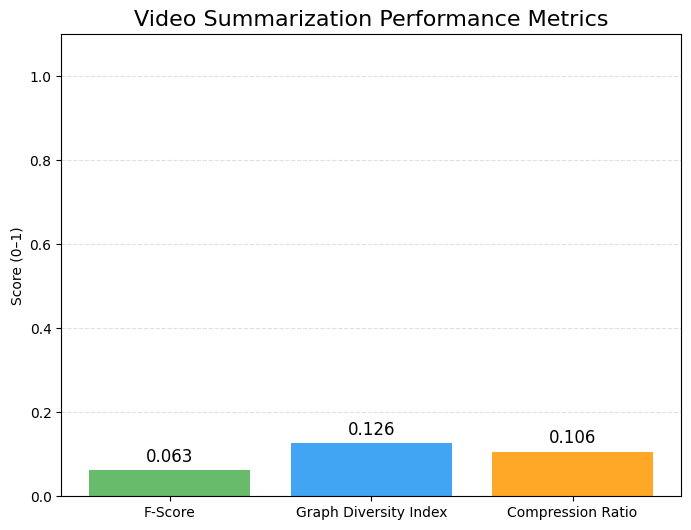

In [15]:
# Names and values for graph
metric_names = ["F-Score", "Graph Diversity Index", "Compression Ratio"]
metric_values = [F_score, GDI, CR]

plt.figure(figsize=(8,6))
bars = plt.bar(metric_names, metric_values, color=["#4CAF50", "#2196F3", "#FF9800"], alpha=0.85)

# Label bars with values
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 0.01, f"{yval:.3f}",
             ha='center', va='bottom', fontsize=12)

plt.ylim(0, 1.1)  # all metrics normalized 0–1
plt.title("Video Summarization Performance Metrics", fontsize=16)
plt.ylabel("Score (0–1)")
plt.grid(axis='y', linestyle='--', alpha=0.4)

plt.show()
